# the workflow

User specify a grid id and date

1. using easyidp to crop point clouds - offsets
2. read the broccoli head position - offsets
3. read the 2D broccoli traits + automl model -> predicted 2D traits
4. find the closest tempalte from the 3D mesh database -> the transfomation + mesh path
5. preview by open3d
5. save previous info to temp file (json / npy)
6. blender python API, read json file, and display

Please use the AMD3090 PC, and ctrl+shift+P connect to WSL server, and using the (lab) enviroment to run this notebook

(Linux auto-sklearn required)

In [43]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(suppress=True)
import pandas as pd
import seaborn as sns
import open3d as o3d

from copy import copy
from shapely.geometry.polygon import Polygon
from scipy.spatial.transform import Rotation 

import easyidp as idp

In [2]:
date = '220405'
grid_id = 45

# 2. read the broccoli head position

In [3]:
from broccoli_file_path import *

In [4]:
idp.shp.show_shp_fields(grid_shp)

  [-1]   [0] id    [1] left      [2] top     [3] right    [4] bottom
------  --------  -----------  -----------  -----------  ------------
     0     1      368059.3728  3956070.552  368061.8728  3956068.052
     1     2      368059.3728  3956068.052  368061.8728  3956065.552
     2     3      368059.3728  3956065.552  368061.8728  3956063.052
   ...    ...         ...          ...          ...          ...
   501    594     368116.8728  3956025.552  368119.3728  3956023.052
   502    595     368116.8728  3956023.052  368119.3728  3956020.552
   503    596     368116.8728  3956020.552  368119.3728  3956018.052


In [5]:
grid = idp.ROI(grid_shp, name_field='id')
grid

[shp][proj] Use projection [WGS 84 / UTM zone 54N] for loaded shapefile [split_grid.shp]


Read shapefile [split_grid.shp]: 100%|██████████| 504/504 [00:15<00:00, 32.47it/s]


<easyidp.ROI> with 504 items
[0]	1
array([[ 368058.59787001, 3956058.88557004],
       [ 368061.04143287, 3956059.41377509],
       [ 368061.56963791, 3956056.97021223],
       [ 368059.12607505, 3956056.44200719],
       [ 368058.59787001, 3956058.88557004]])
[1]	2
array([[ 368059.12607505, 3956056.44200719],
       [ 368061.56963791, 3956056.97021223],
       [ 368062.09784295, 3956054.52664938],
       [ 368059.6542801 , 3956053.99844433],
       [ 368059.12607505, 3956056.44200719]])
...
[502]	595
array([[ 368124.83571154, 3956024.6065918 ],
       [ 368127.27927439, 3956025.13479684],
       [ 368127.80747944, 3956022.69123398],
       [ 368125.36391658, 3956022.16302894],
       [ 368124.83571154, 3956024.6065918 ]])
[503]	596
array([[ 368125.36391658, 3956022.16302894],
       [ 368127.80747944, 3956022.69123398],
       [ 368128.33568448, 3956020.24767113],
       [ 368125.89212163, 3956019.71946608],
       [ 368125.36391658, 3956022.16302894]])

In [6]:
pcd = idp.PointCloud(process_date[date]['pcd'])
pcd

                    x            y        z  r    g    b        nx      ny      nz
        0  368057.379  3956051.919   96.685  177  177  161  nodata  nodata  nodata
        1  368057.405  3956051.796   96.689  144  141  122  nodata  nodata  nodata
        2  368057.403  3956051.803   96.687  141  138  118  nodata  nodata  nodata
      ...     ...          ...      ...      ...  ...  ...     ...     ...     ...
123187743  368133.04   3956019.956   96.643  88   107  78   nodata  nodata  nodata
123187744  368132.9    3956019.851   96.663  114  149  123  nodata  nodata  nodata
123187745  368132.895  3956019.882   96.66   119  115  99   nodata  nodata  nodata

In [7]:
grid_pcd = pcd.crop_point_cloud(grid[grid_id])
grid_pcd._update_btf_print()
grid_pcd

                 x            y        z  r    g    b        nx      ny      nz
     0  368065.365  3956052.669   96.562  42   29   20   nodata  nodata  nodata
     1  368065.346  3956052.665   96.572  62   52   46   nodata  nodata  nodata
     2  368065.355  3956052.668   96.566  64   50   44   nodata  nodata  nodata
   ...     ...          ...      ...      ...  ...  ...     ...     ...     ...
215024  368067.917  3956051.22    96.736  98   112  99   nodata  nodata  nodata
215025  368067.896  3956051.331   96.841  69   74   70   nodata  nodata  nodata
215026  368067.905  3956051.275   96.722  56   53   46   nodata  nodata  nodata

In [8]:
grid_pcd.offset

array([ 368000., 3956000.,       0.])

In [9]:
grid_pcd._points

array([[65.3653, 52.6688, 96.5617],
       [65.346 , 52.6651, 96.5718],
       [65.3554, 52.6679, 96.5657],
       ...,
       [67.9166, 51.2195, 96.7356],
       [67.8956, 51.3313, 96.8406],
       [67.9052, 51.2753, 96.7222]])

calcualte the grid center

In [8]:
grid_ctr = (grid_pcd._points.max(axis=0) + grid_pcd._points.min(axis=0)) / 2
grid_ctr

array([66.5547 , 51.65525, 96.77505])

In [9]:
grid_pcd.update_offset_value(grid_pcd.offset + grid_ctr)

In [12]:
grid_pcd._points

array([[-1.1894 ,  1.01355, -0.21335],
       [-1.2087 ,  1.00985, -0.20325],
       [-1.1993 ,  1.01265, -0.20935],
       ...,
       [ 1.3619 , -0.43575, -0.03945],
       [ 1.3409 , -0.32395,  0.06555],
       [ 1.3505 , -0.37995, -0.05285]])

In [10]:
grid_pcd.offset

array([ 368066.5547 , 3956051.65525,      96.77505])

# 3. read broccoli head positions

In [11]:
broccoli_2d_traits = pd.read_excel('./out/props_all_2022.xlsx')
broccoli_2d_traits.head()

,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,20220321_0,275,2195,2301,0.662845,52.865497,61.468791,46.025174,55.977211,48.827068,183.923882,0.815395,368061.303157,3.956057e+06,28.569196,"[[368061.2815551026, 3956057.0713307424], [368..."
1,20220321_0,274,2512,2655,0.589631,56.554202,63.261803,51.094847,61.040001,52.439999,203.237590,0.764225,368061.039693,3.956057e+06,29.892332,"[[368061.0091929504, 3956057.388480319], [3680..."
2,20220321_0,141,2640,2708,0.486063,57.977171,62.220264,54.375771,62.156914,52.682552,197.438600,0.851039,368060.651307,3.956057e+06,30.560149,"[[368060.6217213799, 3956056.8345038854], [368..."
3,20220321_0,3,1625,1783,0.570272,45.486418,50.724595,41.668026,52.485325,38.600506,169.852814,0.707812,368059.888442,3.956057e+06,25.026932,"[[368059.87077905197, 3956057.177263872], [368..."
4,20220321_0,276,2979,3121,0.390530,61.587179,64.470901,59.351282,62.162289,61.676651,214.066017,0.816930,368061.327088,3.956057e+06,32.678574,"[[368061.2979172566, 3956056.8109018467], [368..."


find out the results in the given grid

In [12]:
grid_xymin = grid[grid_id].min(axis=0)
grid_xymax = grid[grid_id].max(axis=0)

using the min-max bbox to first filter points

In [13]:
in_grid_idx = (broccoli_2d_traits.date == f"20{date}_0") & \
(broccoli_2d_traits.circular_x > grid_xymin[0]) & (broccoli_2d_traits.circular_x < grid_xymax[0]) & \
(broccoli_2d_traits.circular_y > grid_xymin[1]) & (broccoli_2d_traits.circular_y < grid_xymax[1])

In [14]:
broccoli_2d_in_grid = broccoli_2d_traits[in_grid_idx]
print(broccoli_2d_in_grid.shape)
broccoli_2d_in_grid.head()

(33, 16)


,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
35810,20220405_0,833,20672,21471,0.454876,162.235655,172.479149,153.602136,164.053268,163.905670,581.570635,0.768046,368065.219168,3.956051e+06,84.729245,"[[368065.1326798832, 3956051.29927134], [36806..."
35811,20220405_0,832,14473,14882,0.271418,135.748282,138.963896,133.747404,140.579193,134.985550,468.558441,0.828402,368065.121916,3.956052e+06,70.495404,"[[368065.06443522876, 3956051.6657725866], [36..."
35812,20220405_0,835,13738,14208,0.289326,132.256436,135.790101,129.982458,132.826843,128.536301,464.859956,0.798894,368065.364716,3.956051e+06,68.357779,"[[368065.29429905786, 3956050.646875522], [368..."
35813,20220405_0,836,18965,19915,0.534334,155.393011,171.202751,144.713097,165.300674,154.484009,571.600072,0.729421,368065.436652,3.956050e+06,81.821574,"[[368065.352541244, 3956050.244492501], [36806..."
35814,20220405_0,834,14411,14889,0.495827,135.457208,145.901919,126.704309,144.996597,125.647179,477.014285,0.795868,368065.186534,3.956051e+06,70.158017,"[[368065.11606531375, 3956050.9468036722], [36..."


In [15]:
grid_polygon = Polygon(grid[grid_id])
in_grid_poly_inx = []
for i, val in broccoli_2d_in_grid.iterrows():
    bro_head_polygon = Polygon(eval(val.polygon))

    in_grid_poly_inx.append( grid_polygon.contains(bro_head_polygon) )

broccoli_2d_in_grid_poly = broccoli_2d_in_grid[in_grid_poly_inx].reset_index()
broccoli_2d_in_grid_poly.shape
broccoli_2d_in_grid_poly


,index,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,36226,20220405_0,1241,16090,16600,0.297392,143.130794,147.034280,140.381785,144.920578,139.416367,498.173665,0.814712,368067.176536,3.956053e+06,74.998557,"[[368067.11390085274, 3956052.6339732297], [36..."
1,36227,20220405_0,1242,15192,15784,0.408040,139.079312,145.872924,133.176741,144.499802,135.282288,494.658946,0.780213,368067.266380,3.956052e+06,72.150758,"[[368067.1934697727, 3956052.282507738], [3680..."
2,36228,20220405_0,1244,17798,18749,0.190745,150.536100,153.175970,150.363605,154.643265,151.863373,547.771645,0.745387,368067.388565,3.956052e+06,79.438851,"[[368067.3227557869, 3956051.5392689044], [368..."
3,36229,20220405_0,1243,3246,3437,0.746889,64.287911,79.301726,52.731573,78.275551,53.667789,235.823376,0.733474,368067.310496,3.956052e+06,35.659159,"[[368067.27217238705, 3956051.940066062], [368..."
4,36230,20220405_0,1104,17096,17846,0.326035,147.537464,152.390272,144.063330,149.199524,144.956894,526.357431,0.775430,368066.612109,3.956052e+06,76.625155,"[[368066.5434716108, 3956052.3078399547], [368..."
5,36231,20220405_0,1103,15258,15845,0.243462,139.381093,141.943089,137.672076,137.983887,136.086182,502.144228,0.760415,368066.496204,3.956053e+06,73.331649,"[[368066.42560884, 3956052.66962354], [368066...."
6,36232,20220405_0,1108,2773,2959,0.965181,59.419637,121.108022,31.679678,123.479469,32.892342,289.515765,0.415734,368066.939979,3.956051e+06,70.754309,"[[368066.88735818176, 3956050.854874943], [368..."
7,36233,20220405_0,1105,20032,20531,0.252791,159.704523,162.679058,157.395388,159.970428,156.432617,550.600072,0.830351,368066.571870,3.956052e+06,81.951074,"[[368066.500150123, 3956052.0207689838], [3680..."
8,36234,20220405_0,1107,16456,16878,0.321922,144.749542,149.820198,141.844716,144.752731,144.262238,515.457936,0.778301,368066.711394,3.956051e+06,74.064011,"[[368066.64917335554, 3956051.3199445326], [36..."
9,36235,20220405_0,1106,16296,17086,0.464552,144.044131,153.704434,136.112346,153.917786,135.366074,514.600072,0.773306,368066.604574,3.956052e+06,75.830226,"[[368066.54098779114, 3956051.613006014], [368..."


select the necessary part for auto-sklern

In [16]:
# supress SettingWithCopyWarning
pd.set_option('mode.chained_assignment',None)

X = broccoli_2d_in_grid_poly[[
    'major_axis_length', 'minor_axis_length', 
    'min_area_rect_min', 'min_area_rect_max',
    'area', 'convex_area',
]]
X.major_axis_length /= 1000
X.minor_axis_length /= 1000
X.min_area_rect_max /= 1000
X.min_area_rect_min /= 1000
X.area /= 100
X.convex_area /= 100

X.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,0.147034,0.140382,0.139416,0.144921,160.90,166.00
1,0.145873,0.133177,0.135282,0.144500,151.92,157.84
2,0.153176,0.150364,0.151863,0.154643,177.98,187.49
3,0.079302,0.052732,0.053668,0.078276,32.46,34.37
4,0.152390,0.144063,0.144957,0.149200,170.96,178.46


load the auto-sklearn model"

In [17]:
with open('out/autoskl_model_1.pkl', 'rb') as handle:
    automl = pickle.load(handle)

In [18]:
predictions = automl.predict(X.values)

predictions = pd.DataFrame(columns=X.columns, data=predictions)
predictions.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,0.152488,0.144988,0.143025,0.145358,166.861453,169.793249
1,0.150608,0.144283,0.145149,0.141020,163.174965,166.850514
2,0.160536,0.145413,0.153131,0.144844,177.298783,179.950861
3,0.104284,0.095855,0.096153,0.096114,76.499159,80.725834
4,0.161362,0.151353,0.148678,0.153769,186.311048,188.362541


preview the data distribution

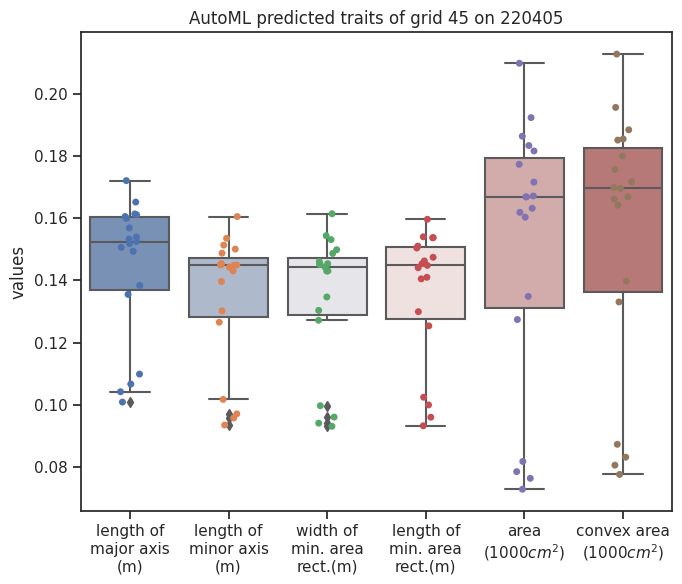

In [19]:
sns.set_theme(style="ticks")

predictions4plot = predictions.copy()
predictions4plot.area /= 1000
predictions4plot.convex_area /= 1000

predictions4plot = predictions4plot.rename(columns={
    'major_axis_length': 'length of\nmajor axis\n(m)', 
    'minor_axis_length': 'length of\nminor axis\n(m)', 
    'min_area_rect_min': 'width of\nmin. area\nrect.(m)',
    'min_area_rect_max': 'length of\nmin. area\nrect.(m)', 
    'area': 'area\n($1000 cm^2$)', 
    'convex_area': 'convex area\n($1000 cm^2$)',
})

f, ax = plt.subplots(figsize=(7, 6))

sns.boxplot(data=predictions4plot, ax=ax, palette="vlag")
sns.stripplot(data=predictions4plot, ax=ax)

# plt.xticks(rotation=-45)

ax.set_title(f'AutoML predicted traits of grid {grid_id} on {date}')
ax.set_ylabel('values')

plt.tight_layout()
plt.savefig(f'out/autoskl_pred_{date}_{grid_id}.svg')
plt.show()

# 4. find the closest database

load the database

In [20]:
broccoli_mesh_db = pd.read_excel('out/autoskl_model_db.xlsx')
broccoli_mesh_db

,Date,Field_ID,Model_ID,long_axis(m),short_axis(m),crown_roundness,orientation(degree),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),head_height(m),crown_height(m),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),head_3dconcave_volume(cm3)
0,20220317,8574,3-1,0.073558,0.062972,0.798339,-65.296804,0.063708,0.061781,31.835893,35.111111,0.142084,0.050574,90.544264,31.423250,42.108040
1,20220317,8575,3-2,0.059003,0.051484,0.930713,-176.139473,0.045497,0.052653,19.398061,23.666667,0.149868,0.040657,50.526204,25.778741,19.931228
2,20220317,8576,3-3,0.052651,0.049139,0.908292,-80.964335,0.048661,0.045269,17.632555,20.111111,0.147616,0.039791,39.632416,14.129421,127.465372
3,20220317,8577,3-4,0.060120,0.053417,0.889342,-78.029467,0.047834,0.053833,20.411755,25.000000,0.146556,0.038978,50.215150,18.277578,50.012442
4,20220317,8578,3-5,0.063628,0.059194,0.920256,-2.246206,0.054661,0.059125,26.335788,29.333333,0.156164,0.047445,73.213668,32.829862,84.052978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,20220405,5593,8-32,0.154418,0.152340,0.744710,-2.194721,0.145620,0.156182,179.199750,180.222222,0.157322,0.096966,1091.146271,15.990872,49.056136
184,20220405,5594,8-33,0.176361,0.152302,0.797066,-93.464791,0.150877,0.167778,203.381424,208.555556,0.165034,0.125175,1372.151591,34.448384,11.887970
185,20220405,10233,9-31,0.154003,0.142144,0.726698,-62.778655,0.149875,0.138550,167.302718,168.888889,0.178237,0.133220,1356.690145,44.955292,15.085098
186,20220405,10234,9-32,0.152286,0.149501,0.670645,-156.820172,0.151497,0.143503,172.877534,174.777778,0.181256,0.096029,1000.206070,42.004512,9.575636


In [21]:
matching_sort = broccoli_mesh_db[[
     'long_axis(m)', 'short_axis(m)', # 'crown_roundness',
     'min_rect_width(m)', 'min_rect_length(m)', 
     'crown_2dconvex_area(cm2)', 'projected_leaf_area(cm2)']]
matching_sort

,long_axis(m),short_axis(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2)
0,0.073558,0.062972,0.063708,0.061781,31.835893,35.111111
1,0.059003,0.051484,0.045497,0.052653,19.398061,23.666667
2,0.052651,0.049139,0.048661,0.045269,17.632555,20.111111
3,0.060120,0.053417,0.047834,0.053833,20.411755,25.000000
4,0.063628,0.059194,0.054661,0.059125,26.335788,29.333333
...,...,...,...,...,...,...
183,0.154418,0.152340,0.145620,0.156182,179.199750,180.222222
184,0.176361,0.152302,0.150877,0.167778,203.381424,208.555556
185,0.154003,0.142144,0.149875,0.138550,167.302718,168.888889
186,0.152286,0.149501,0.151497,0.143503,172.877534,174.777778


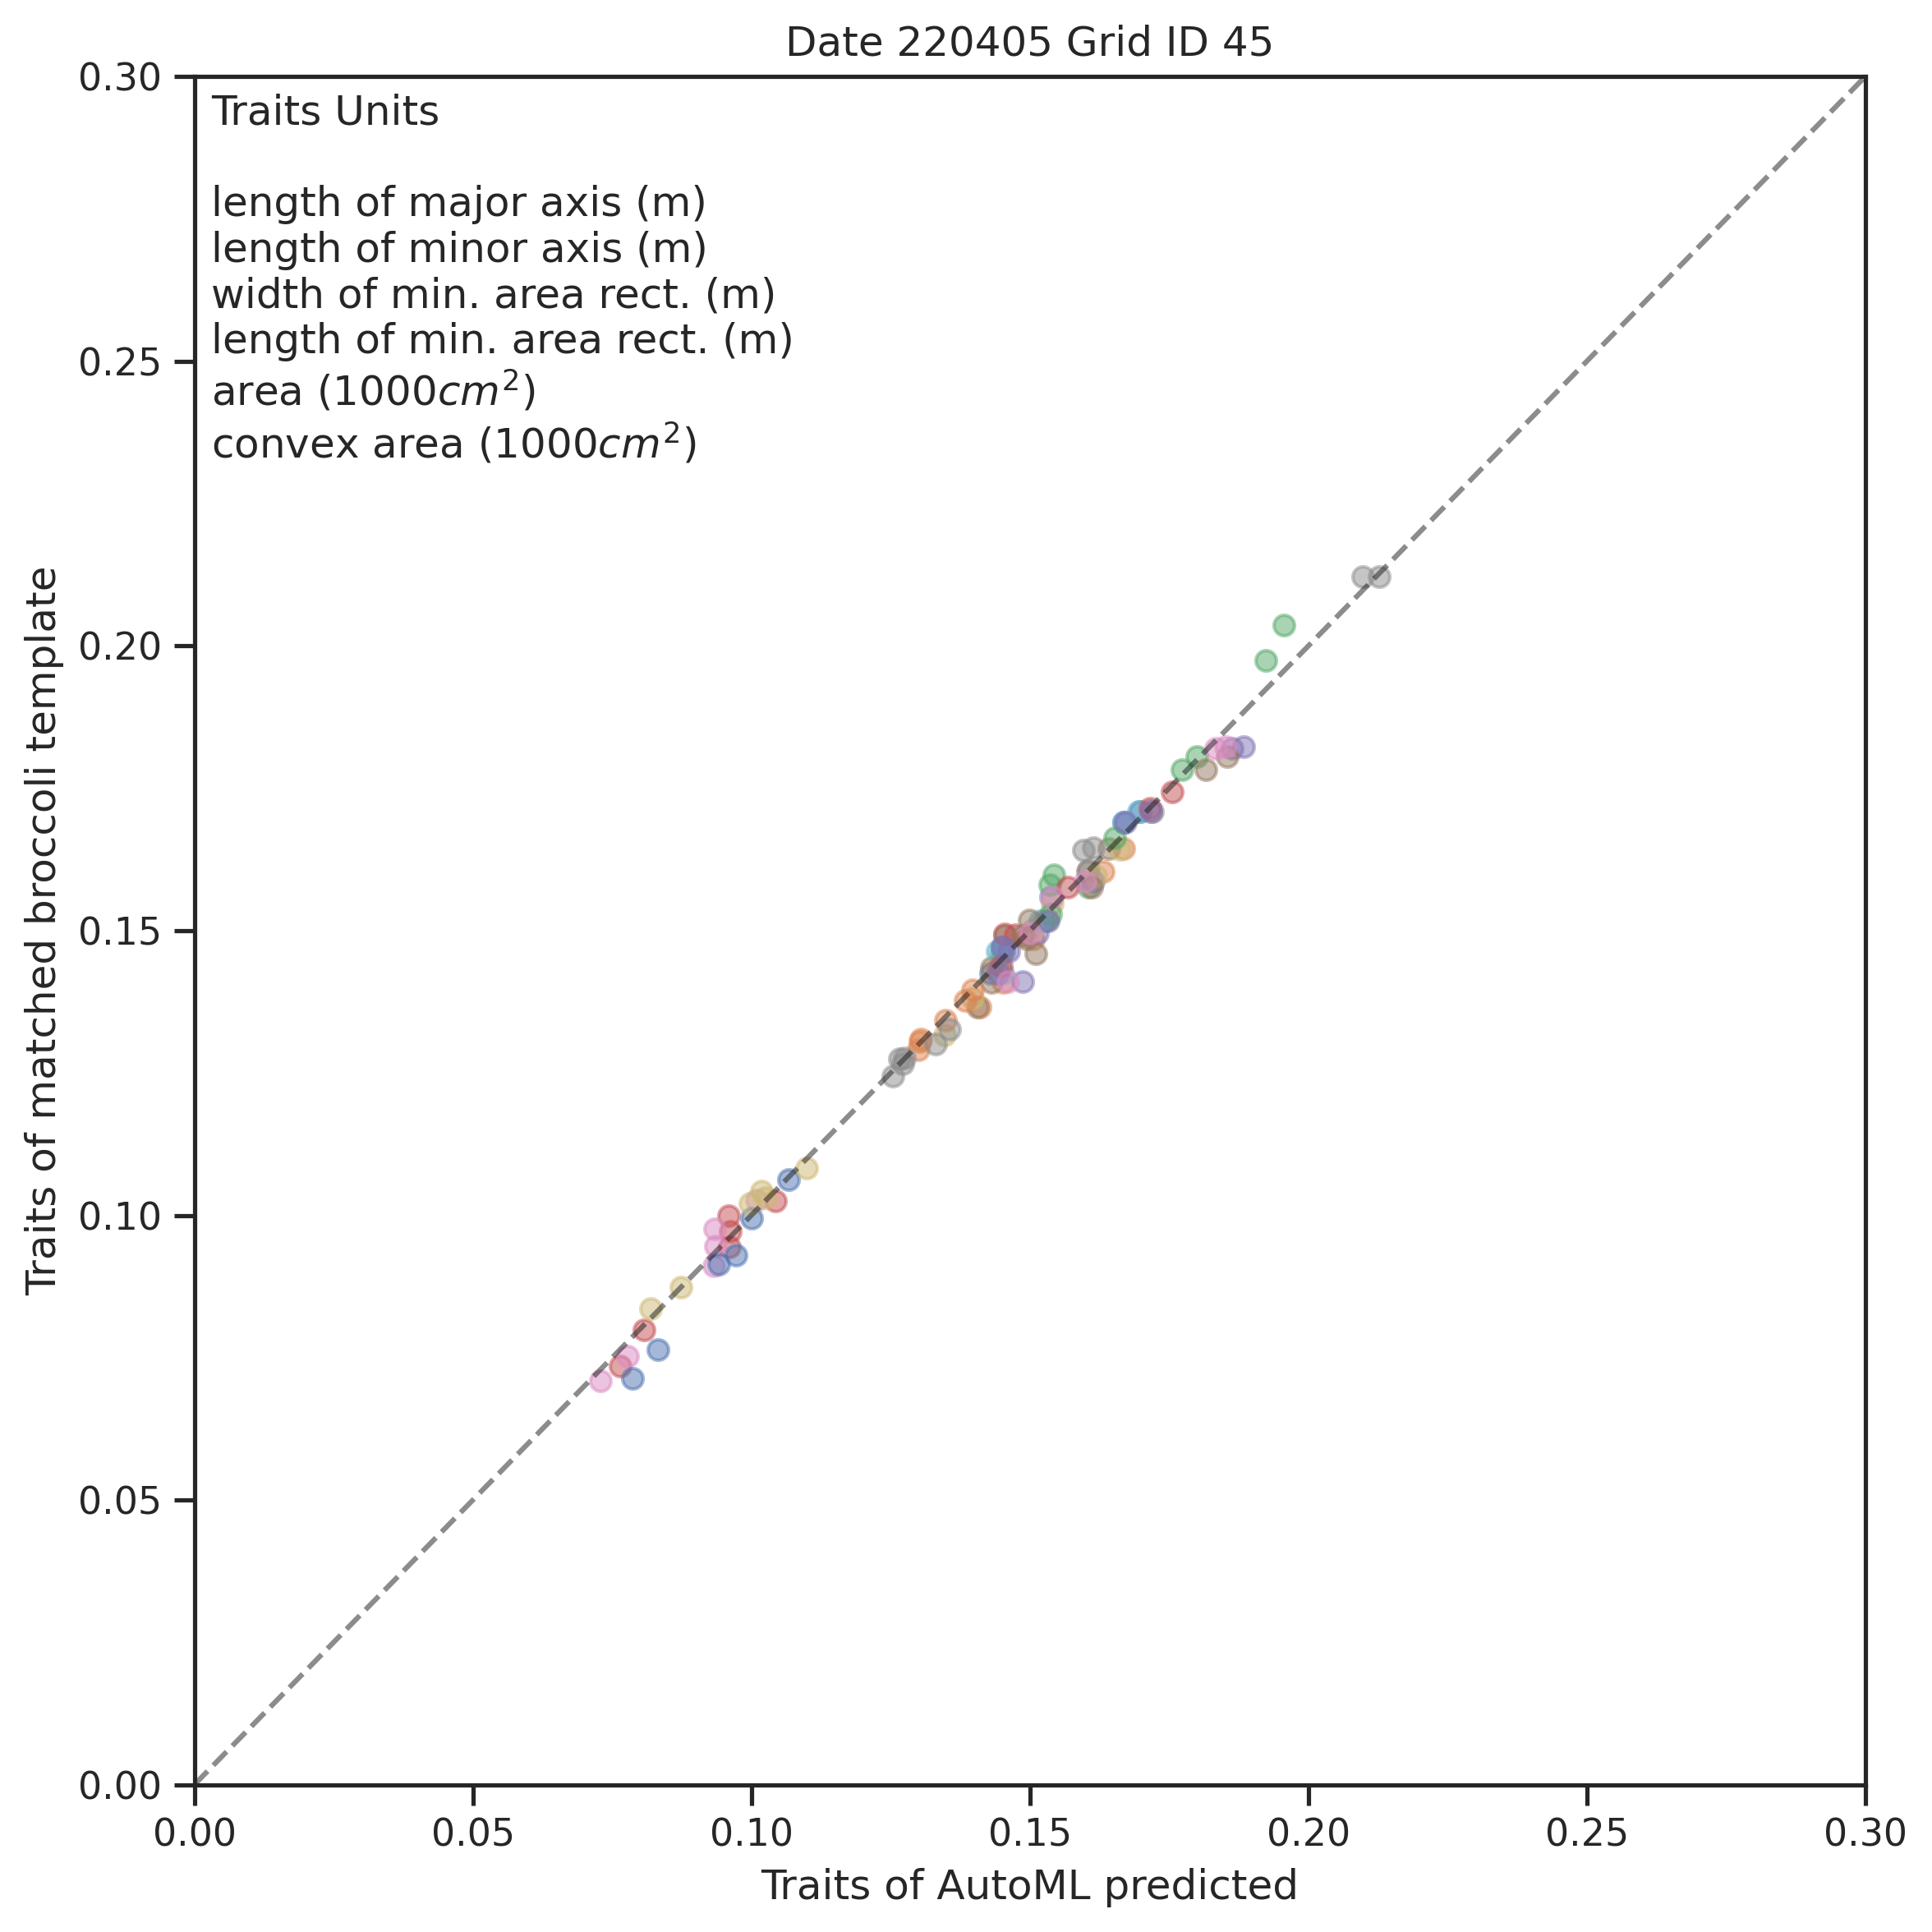

In [22]:
fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)

trans = []
matched_idx = []

lbmax = np.ceil( 0.01 * matching_sort.values.max()) / 10

ax.plot([0, lbmax], [0, lbmax], 'k--', alpha=0.5)

for row_id, v in predictions.iterrows():
    diff = matching_sort.values - v.values
    # normalize
    diff_norm = np.abs(diff / np.linalg.norm(diff, axis=0))
    diff_sum = diff_norm.sum(axis=1)

    min_diff_idx = np.argmin(diff_sum)

    pred_v = v.values
    db_v = matching_sort.values[min_diff_idx,:]

    plot_ratio = np.array([1, 1, 1, 1, 0.001, 0.001])
    ax.scatter(x=pred_v*plot_ratio, y=db_v*plot_ratio, alpha=0.5)

    # [2]'min_rect_width(m)', [3] 'min_rect_length(m)', 
    trans.append((pred_v[2]/db_v[2], pred_v[3]/db_v[3]))
    matched_idx.append(min_diff_idx)
    
ax.set_xlim(0, lbmax)
ax.set_ylim(0, lbmax)

ax.text(lbmax*0.01, lbmax*0.99, 
    'Traits Units \n\n'
    'length of major axis (m)\n' + 
    'length of minor axis (m)\n' + 
    'width of min. area rect. (m)\n' + 
    'length of min. area rect. (m)\n'+ 
    'area ($1000cm^2$)\n' + 
    'convex area ($1000cm^2$)\n',
    va='top')
ax.set_xlabel('Traits of AutoML predicted')
ax.set_ylabel('Traits of matched broccoli template')
ax.set_title(f'Date {date} Grid ID {grid_id}')
plt.tight_layout()
plt.savefig(f"out/autoskl_matched_{date}_{grid_id}.svg")
plt.show()

In [23]:
trans

[(1.0037756468508814, 0.9933085889693246),
 (1.0304686888872079, 1.0322382445378047),
 (1.007979731711809, 0.9926604196814525),
 (0.9887650773345604, 1.0168898583107266),
 (1.0545273395712753, 0.9860809571612605),
 (1.0157554498840562, 1.028642810585259),
 (1.0222854389666012, 0.9560971836083095),
 (0.9811280365056824, 0.9731088904145302),
 (1.0235570818986082, 1.002022033963056),
 (1.0184474186867196, 0.9846591197989887),
 (1.0304097341688538, 1.006285893741809),
 (0.9954083714867609, 1.0074754836527047),
 (0.965744999260592, 1.0051616419694143),
 (0.9727825261572232, 0.9875125228778914),
 (1.0121317810688755, 0.9995549955785468),
 (0.9865663437207268, 1.0351389190720295),
 (1.0360281702705878, 0.9876811318641128),
 (1.0043209643824638, 1.0081298588785623),
 (0.9776846375617665, 0.9949606577760881)]

combine scales + positions (translate)

In [24]:
for i, row in broccoli_2d_in_grid_poly.iterrows():
    print(row)

    break

index                                                              36226
date                                                          20220405_0
label                                                               1241
area                                                               16090
convex_area                                                        16600
eccentricity                                                    0.297392
equivalent_diameter                                           143.130794
major_axis_length                                              147.03428
minor_axis_length                                             140.381785
min_area_rect_max                                             144.920578
min_area_rect_min                                             139.416367
perimeter                                                     498.173665
circularity                                                     0.814712
circular_x                                         

In [36]:
polygon_np = np.array(eval(row.polygon))

In [42]:
polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
polygon_xyz

              x            y        z  r       g       b           nx      ny      nz
  0  368067.12   3956052.715   96.971  nodata  nodata  nodata  nodata  nodata  nodata
  1  368067.138  3956052.716   96.968  nodata  nodata  nodata  nodata  nodata  nodata
  2  368067.121  3956052.725   96.958  nodata  nodata  nodata  nodata  nodata  nodata
...     ...          ...      ...      ...     ...     ...        ...     ...     ...
673  368067.228  3956052.652   96.962  nodata  nodata  nodata  nodata  nodata  nodata
674  368067.206  3956052.612   96.965  nodata  nodata  nodata  nodata  nodata  nodata
675  368067.217  3956052.72    96.946  nodata  nodata  nodata  nodata  nodata  nodata

(array([ 20.,  18.,   0.,   0.,   0.,   0.,   0.,  33., 255., 350.]),
 array([96.6995, 96.7288, 96.7581, 96.7874, 96.8167, 96.846 , 96.8753,
        96.9046, 96.9339, 96.9632, 96.9925]),
 <BarContainer object of 10 artists>)

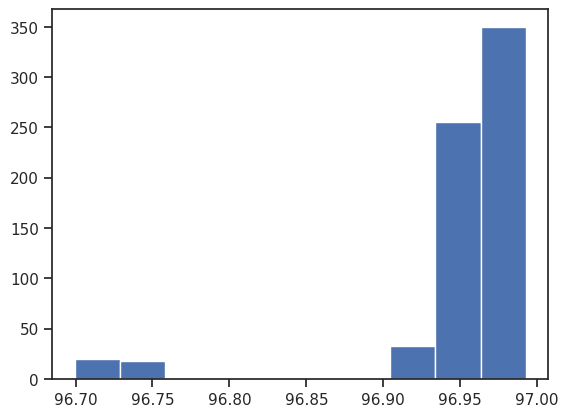

In [46]:
plt.hist(polygon_xyz.points[:,2])

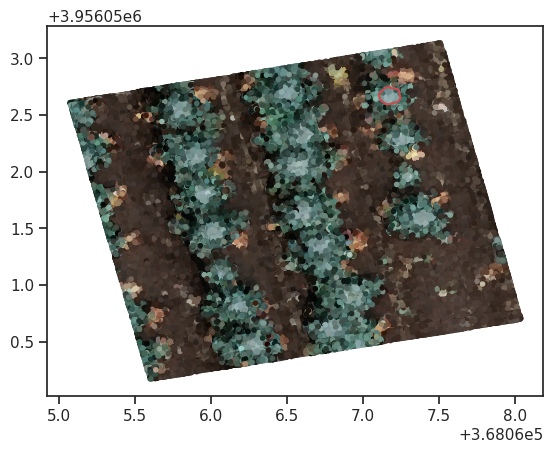

In [41]:
plt.scatter(grid_pcd.points[:,0], grid_pcd.points[:,1], color=grid_pcd.colors/255, marker='.')
plt.plot(*polygon_np.T, color='r')

In [26]:
for i, row in broccoli_2d_in_grid_poly.iterrows():
    polygon_np = np.array(eval(row.polygon))
    polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
    ht_values = polygon_xyz.points[:,2]

    # 95% percentile ht
    thresh = np.percentile(ht_values, 95, axis=0)
    z_pos = np.mean(ht_values[ht_values >= thresh])

    # offseted
    x_pos = row.circular_x - grid_pcd.offset[0]
    y_pos = row.circular_y - grid_pcd.offset[1]
    z_pos -= grid_pcd.offset[2]

    print(x_pos, y_pos, z_pos)

    break

0.6218362894142047 1.0159400603733957 0.21458235294117856


In [50]:
grid_pcd.offset

array([ 368066.5547 , 3956051.65525,      96.77505])

In [27]:
def to_open3d(idp_pcd):
    final_pcd = o3d.geometry.PointCloud()
    final_pcd.points = o3d.utility.Vector3dVector(idp_pcd._points)
    color_np = idp_pcd.colors/255
    # color_np = np.insert(color_np, 2, 0.5, axis=1)
    # print(color_np)
    final_pcd.colors = o3d.utility.Vector3dVector(color_np)

    return final_pcd

In [28]:
grid_pcd_o3d = to_open3d(grid_pcd)

In [58]:
o3d.visualization.draw_geometries([grid_pcd_o3d])

find the mesh models

In [29]:
mesh_database_path = r"out/v230407/ztopmash"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [30]:
matched_slice = broccoli_mesh_db.iloc[matched_idx[i]]
matched_slice

Date                              20220405
Field_ID                              5515
Model_ID                              2-33
long_axis(m)                      0.151781
short_axis(m)                     0.147068
crown_roundness                    0.64944
orientation(degree)             -90.707964
min_rect_width(m)                 0.142487
min_rect_length(m)                0.146337
crown_2dconvex_area(cm2)        169.044826
projected_leaf_area(cm2)        170.888889
head_height(m)                      0.1734
crown_height(m)                   0.113143
crown_3dconvex_volume(cm3)     1112.297955
crown_3dconcave_volume(cm3)      17.695664
head_3dconcave_volume(cm3)       34.413316
Name: 166, dtype: object

In [56]:
line_set = o3d.geometry.LineSet()

line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [32]:
mesh_db[matched_slice.Model_ID]

'out/v230407/ztopmash/2-33.obj'

In [33]:
mesh = o3d.io.read_triangle_mesh(mesh_db[matched_slice.Model_ID],  enable_post_processing=True)

In [34]:
o3d.visualization.draw_geometries([line_set, mesh])

In [42]:
r = Rotation.from_euler('z', matched_slice['orientation(degree)'], degrees=True)
r.as_matrix()

array([[-0.01235599,  0.99992366,  0.        ],
       [-0.99992366, -0.01235599, -0.        ],
       [-0.        ,  0.        ,  1.        ]])

In [68]:
r.inv().as_matrix()

array([[-0.01235599, -0.99992366, -0.        ],
       [ 0.99992366, -0.01235599,  0.        ],
       [ 0.        , -0.        ,  1.        ]])

In [78]:
m_trans = copy(mesh).rotate(r.as_matrix())

# scale
m_trans.vertices = o3d.utility.Vector3dVector(
    np.asarray(m_trans.vertices) * np.array([trans[i][0], trans[i][1], 1]) 
)
# by testing, the x -> width, y -> length
# trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
m_trans_back = copy(m_trans).rotate(r.inv().as_matrix())

In [79]:
o3d.visualization.draw_geometries([line_set, mesh, m_trans.translate((0, 0.2, 0)),  m_trans_back.translate((0.2, 0, 0))])

In [39]:
# phi = matched_slice['orientation(degree)']
# trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
# maj_x = np.cos(np.deg2rad(phi)) * trans[i][1] # major_axis
# maj_y = np.sin(np.deg2rad(phi)) * trans[i][1] # major_axis
# min_x = np.sin(np.deg2rad(phi)) * trans[i][0] # plant.minor_axis
# min_y = np.cos(np.deg2rad(phi)) * trans[i][0] # plant.minor_axis

# print(phi, maj_x, maj_y, min_x, min_y)

-90.70796401410178 -0.012273309612556633 -0.9932327616381695 -1.0036990204839855 -0.012402640460532282


In [87]:
o3d.visualization.draw_geometries([
    grid_pcd_o3d, 
    mesh.translate((x_pos, y_pos, z_pos))])

In [80]:
broccoli_mesh_container = []
for i, row in broccoli_2d_in_grid_poly.iterrows():
    polygon_np = np.array(eval(row.polygon))
    polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
    ht_values = polygon_xyz.points[:,2]

    # 95% percentile ht
    thresh = np.percentile(ht_values, 95, axis=0)
    z_pos = np.mean(ht_values[ht_values >= thresh])

    # offseted
    x_pos = row.circular_x - grid_pcd.offset[0]
    y_pos = row.circular_y - grid_pcd.offset[1]
    z_pos -= grid_pcd.offset[2]

    # find
    matched_slice = broccoli_mesh_db.iloc[matched_idx[i]]
    mesh = o3d.io.read_triangle_mesh(mesh_db[matched_slice.Model_ID],  enable_post_processing=True)

    r = Rotation.from_euler('z', matched_slice['orientation(degree)'], degrees=True)
    m_trans = copy(mesh).rotate(r.as_matrix())

    # scale
    m_trans.vertices = o3d.utility.Vector3dVector(
        np.asarray(m_trans.vertices) * np.array([trans[i][0], trans[i][1], 1]) 
    )
    # by testing, the x -> width, y -> length
    # trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
    m_trans_back = copy(m_trans).rotate(r.inv().as_matrix())

    broccoli_mesh_container.append(m_trans_back.translate((x_pos, y_pos, z_pos)))

In [81]:
o3d.visualization.draw_geometries([grid_pcd_o3d] + broccoli_mesh_container)

# 5. preview by open3d